# 😀 Reconocimiento de emociones faciales con redes convolucionales

### Visión por Computador ·  Universidad de Santiago de Chile
**Diego** — material adaptado para el curso, sobre la base del trabajo de Domingo Mery.

---

En este cuaderno entrenamos (y/o cargamos) una **red neuronal convolucional (CNN)** capaz de
clasificar la expresión facial de una persona en una de **siete categorías** del conjunto
**FER2013** (*Facial Expression Recognition 2013*):

| Índice | Inglés (modelo) | Español |
|:---:|:---|:---|
| 0 | Angry | Enojo |
| 1 | Disgust | Asco |
| 2 | Fear | Miedo |
| 3 | Happy | Felicidad |
| 4 | Sad | Tristeza |
| 5 | Surprise | Sorpresa |
| 6 | Neutral | Neutral |

**Recorrido del cuaderno**

1. Descargar el repositorio de apoyo y el dataset FER2013.
2. Preparar y explorar los datos (imágenes de 48×48 px en escala de grises).
3. Definir y entrenar la arquitectura CNN — *o* cargar un modelo ya entrenado.
4. Evaluar el modelo (curvas, exactitud, matriz de confusión, reporte por clase).
5. Probar con imágenes reales, incluida **una foto tuya**.
6. Discutir los **límites éticos y científicos** del reconocimiento de emociones.

> ⚠️ **Antes de ejecutar:** ve a `Entorno de ejecución → Cambiar tipo de entorno` y
> selecciona una **GPU**. El entrenamiento desde cero es mucho más lento en CPU.
> Si prefieres no entrenar, puedes saltar directo a la **sección 7** y usar el modelo preentrenado.

## 1. Preparación: repositorio y dataset

Clonamos el repositorio de apoyo (contiene el detector de rostros de Haar, imágenes de
prueba y emojis) y descargamos el dataset **FER2013** en formato CSV.

In [ ]:
# Clonamos el repositorio de apoyo (detector Haar, imágenes de prueba, emojis)
!git clone https://github.com/esra-polat/facial-emotion-recognition.git

Cloning into 'facial-emotion-recognition'...
remote: Enumerating objects: 34161, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 34161 (delta 25), reused 99 (delta 25), pack-reused 34062 (from 1)
Receiving objects: 100% (34161/34161), 56.31 MiB | 13.46 MiB/s, done.
Resolving deltas: 100% (30/30), done.


In [ ]:
# Descargamos el dataset FER2013 (≈ 28.000 imágenes etiquetadas)
!wget -q -O 'fer.2013.zip' \
 https://www.dropbox.com/scl/fi/t4v64uk6xze1i9yrni7gf/fer2013.csv.zip?rlkey=drvqbek3jy9824jy6lcest8ls&st=5kv16k2l&dl=0
!unzip 'fer.2013.zip'

Archive:  fer.2013.zip
  inflating: fer2013.csv             


## 2. Importación de librerías

Usamos **Keras/TensorFlow** para la red, **scikit-learn** para la partición de datos y las
métricas, **OpenCV** para el procesamiento de imágenes y **matplotlib** para las visualizaciones.

In [ ]:
from __future__ import division
import sys, os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

%matplotlib inline
import matplotlib.pyplot as plt

from google.colab.patches import cv2_imshow
import cv2

from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from keras.losses import categorical_crossentropy
from keras.optimizers import Adam
from keras.regularizers import l2
from keras.callbacks import ReduceLROnPlateau, TensorBoard, EarlyStopping, ModelCheckpoint
from keras.models import load_model
from keras.models import model_from_json

import itertools
from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")

## 3. Carga y preparación de FER2013

El CSV trae cada imagen como una **cadena de 2.304 números** (48×48 = 2304) separados por
espacios. La convertimos a un arreglo de `48×48`, le agregamos el canal de color (escala de
grises → 1 canal) y transformamos las etiquetas a formato **one-hot** (un vector de 7 posiciones).

In [ ]:
dataset = pd.read_csv('fer2013.csv')
# ancho, alto
w, h = 48, 48
X = []

# extraemos las características (píxeles) para el entrenamiento
for i in dataset['pixels'].tolist():
    x_val = [int(xp) for xp in i.split(' ')]
    x_val = np.asarray(x_val).reshape(w, h)
    X.append(x_val.astype('float32'))

X = np.asarray(X)
X = np.expand_dims(X, -1)

# etiquetas de emoción en formato one-hot
y = pd.get_dummies(dataset['emotion']).to_numpy()

print("Imágenes:", X.shape, " Etiquetas:", y.shape)

Imágenes: (35887, 48, 48, 1)  Etiquetas: (35887, 7)


### 3.1 Explorando el dataset 🔍

Antes de entrenar conviene mirar **cuántos ejemplos hay de cada emoción**. FER2013 está
**fuertemente desbalanceado**: *Felicidad* tiene miles de ejemplos, mientras que *Asco* apenas
unos cientos. Esto es importante: el modelo aprenderá mucho mejor las clases abundantes y le
costará las escasas — algo que veremos reflejado más adelante en la matriz de confusión.

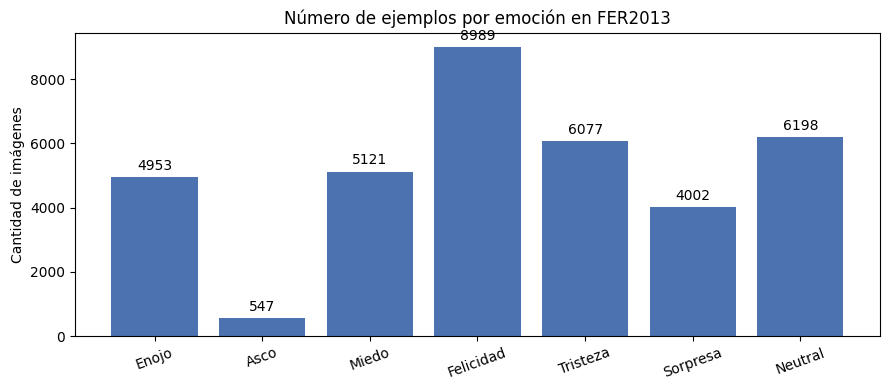

Clase más frecuente: Felicidad
Clase menos frecuente: Asco


In [ ]:
# Distribución de clases en FER2013
etiquetas_es = ['Enojo', 'Asco', 'Miedo', 'Felicidad', 'Tristeza', 'Sorpresa', 'Neutral']
conteos = dataset['emotion'].value_counts().sort_index()

plt.figure(figsize=(9, 4))
barras = plt.bar(etiquetas_es, conteos.values, color='#4C72B0')
plt.bar_label(barras, padding=3)
plt.title('Número de ejemplos por emoción en FER2013')
plt.ylabel('Cantidad de imágenes')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Clase más frecuente:", etiquetas_es[conteos.idxmax()])
print("Clase menos frecuente:", etiquetas_es[conteos.idxmin()])

## 4. Normalización y vistazo a las muestras

Guardamos los arreglos con NumPy, los **estandarizamos** (restamos la media y dividimos por la
desviación estándar de cada píxel) y mostramos un mosaico de 25 caras para confirmar que todo
quedó bien cargado.

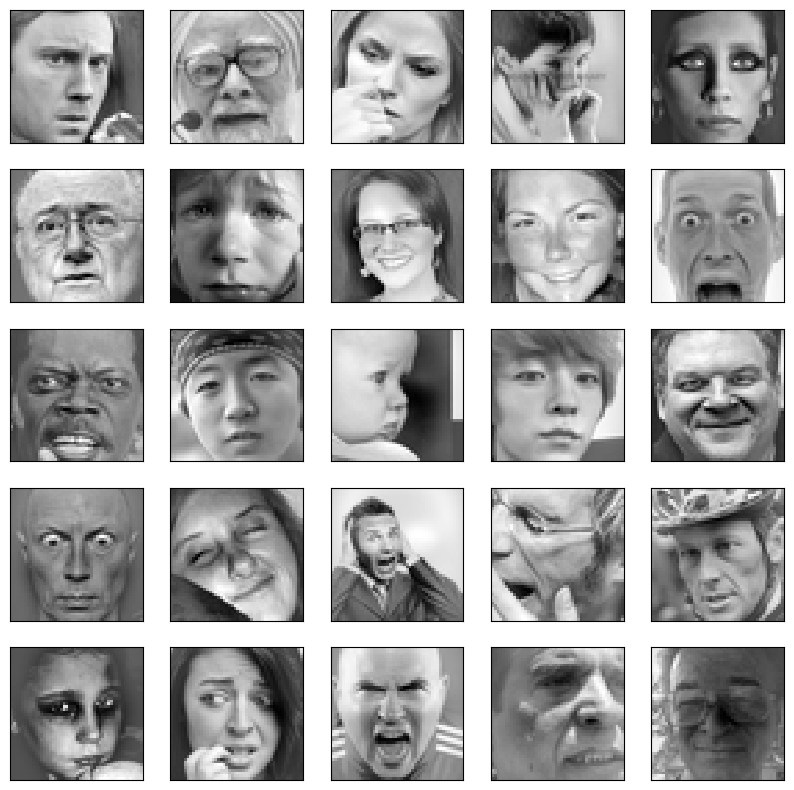

In [ ]:
# guardamos con numpy
np.save('facial-emotion-recognition/model/x_hypo', X)  # datos
np.save('facial-emotion-recognition/model/y_hypo', y)  # etiquetas

x = np.load('facial-emotion-recognition/model/x_hypo.npy')
y = np.load('facial-emotion-recognition/model/y_hypo.npy')

# estandarización por píxel
x -= np.mean(x, axis=0)
x /= np.std(x, axis=0)

# verificamos visualmente los datos
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x[i].reshape((48, 48)), interpolation='none', cmap='gray')
plt.show()

## 5. Arquitectura de la red convolucional

Partimos los datos en **entrenamiento / validación / prueba** y definimos una CNN profunda.
La idea general:

- **Bloques convolucionales** que duplican los filtros (64 → 128 → 256 → 512 → 1024) y van
  reduciendo la resolución con `MaxPooling`.
- `BatchNormalization` para estabilizar el entrenamiento y `Dropout` para combatir el
  sobreajuste (regularización).
- Una **cabeza densa** que termina en 7 neuronas con activación `softmax` (una por emoción).

In [ ]:

#splitting into training, validation and testing data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.1, random_state=41)

#saving the test sample
np.save('facial-emotion-recognition/model/X_test', X_test)
np.save('facial-emotion-recognition/model/y_test', y_test)

#desinging the CNN

#stack for layers
model = Sequential()

#input layer
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=(w, h, 1), data_format='channels_last', kernel_regularizer=l2(0.01)))
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.5))

#hidden layer1
model.add(Conv2D(2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.5))

#hidden layer2
model.add(Conv2D(2*2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(2*2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.5))

#hidden layer3
model.add(Conv2D(2*2*2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(2*2*2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.5))

#hidden layer4
model.add(Conv2D(2*2*2*2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(Conv2D(2*2*2*2*64, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
model.add(Dropout(0.5))

#dense layer / classification
model.add(Flatten())

model.add(Dense(2*2*2*2*64, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(2*2*2*64, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(2*2*64, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(2*64, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(7, activation='softmax'))

model.summary()

## 6. Compilación

Usamos el optimizador **Adam**, la pérdida `categorical_crossentropy` (clasificación
multiclase con etiquetas one-hot) y seguimos la métrica de **exactitud** (*accuracy*).

In [ ]:
model.compile(loss=categorical_crossentropy,
              optimizer=Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-7),
              metrics=['accuracy'])

## 7. Entrenamiento

Entrenamos por 100 épocas. ⏳ **Esto toma bastante tiempo**, incluso con GPU.

> 💡 **¿Apuradx?** Puedes **saltarte esta celda** (y las dos siguientes) e ir directo a la
> **sección 8**, donde descargamos un modelo ya entrenado.

In [ ]:
# entrenamiento del modelo
history = model.fit(np.array(X_train), np.array(y_train),
          batch_size=64,
          epochs=100,
          verbose=1,
          validation_data=(np.array(X_valid), np.array(y_valid)),
          shuffle=True)

### 7.1 Guardar el modelo recién entrenado

In [ ]:
# guardamos el modelo (arquitectura + pesos)
fer_json = model.to_json()
with open("facial-emotion-recognition/model/fer.json", "w") as json_file:
    json_file.write(fer_json)
model.save_weights("facial-emotion-recognition/model/model.weights.h5")

### 7.2 Curvas de entrenamiento

Comparamos la exactitud en **entrenamiento** vs. **validación** época a época. Si la curva de
entrenamiento sube mucho más que la de validación, es señal de **sobreajuste**.

In [ ]:
# evaluamos el modelo
plt.plot(history.history['accuracy'], label='entrenamiento')
plt.plot(history.history['val_accuracy'], label='validación')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(X_valid, y_valid, verbose=2)
print("Exactitud en validación:", test_acc)

## 8. Atajo: descargar un modelo ya entrenado

Si saltaste el entrenamiento (o quieres reproducir resultados consistentes), aquí descargamos
los pesos preentrenados y los dejamos en la carpeta `model/`.

In [ ]:
!wget -q -O 'model.zip' \
  https://www.dropbox.com/scl/fi/qqnf015q3suxtsaoyzjuy/model.zip?rlkey=g2fnaimecge1hcosq6noneir8&st=9531k8bm&dl=0
!unzip model.zip

Archive:  model.zip
   creating: model/
  inflating: model/fer.json          
  inflating: model/model.weights.h5  
  inflating: model/x_hypo.npy        
  inflating: model/X_test.npy        
  inflating: model/y_hypo.npy        
  inflating: model/y_test.npy        


In [ ]:
!mv model/fer.json facial-emotion-recognition/model/fer.json
!mv model/model.weights.h5 facial-emotion-recognition/model/model.weights.h5
!mv model/X_test.npy facial-emotion-recognition/model/X_test.npy
!mv model/y_test.npy facial-emotion-recognition/model/y_test.npy
!mv model/x_hypo.npy facial-emotion-recognition/model/x_hypo.npy
!mv model/y_hypo.npy facial-emotion-recognition/model/y_hypo.npy

## 9. Cargar el modelo

Reconstruimos el modelo desde el archivo `fer.json` (arquitectura) y le cargamos los pesos
`.h5`. Luego predecimos sobre el conjunto de prueba.

In [ ]:
# cargamos el modelo
json_file = open('facial-emotion-recognition/model/fer.json', 'r')
model_json = json_file.read()
json_file.close()
model = model_from_json(model_json)
# cargamos los pesos en el modelo
model.load_weights("facial-emotion-recognition/model/model.weights.h5")

true_y = []
pred_y = []

x_test_acc = np.load('facial-emotion-recognition/model/X_test.npy')
y_test_acc = np.load('facial-emotion-recognition/model/y_test.npy')

y_tmp = model.predict(x_test_acc)
yh = y_tmp.tolist()
yt = y.tolist()

113/113 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step


## 10. Reconocer la emoción en una imagen

Flujo:
- Detectar el rostro
- Recortarlo
- Escalar a 48×48 px en escala de grises
- Predecir con la CNN

In [ ]:
# etiquetas del modelo (orden FER2013) y su traducción
labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
labels_es = ['Enojo', 'Asco', 'Miedo', 'Felicidad', 'Tristeza', 'Sorpresa', 'Neutral']

# cargamos la imagen de prueba
image = cv2.resize(cv2.imread('facial-emotion-recognition/test_pictures/test.jpg'), (225, 225))

full_size_image = cv2.imread('facial-emotion-recognition/test_pictures/test.jpg')
print("Imagen cargada")
gray = cv2.cvtColor(full_size_image, cv2.COLOR_RGB2GRAY)
face = cv2.CascadeClassifier('facial-emotion-recognition/data_operations/haarcascade_frontalface_default.xml')
faces = face.detectMultiScale(gray, 1.3, 10)

emotion = ""

# detectamos los rostros
for (x, y, w, h) in faces:
        roi_gray = gray[y:y + h, x:x + w]
        cropped_img = np.expand_dims(np.expand_dims(cv2.resize(roi_gray, (48, 48)), -1), 0)
        cv2.normalize(cropped_img, cropped_img, alpha=0, beta=1, norm_type=cv2.NORM_L2, dtype=cv2.CV_32F)
        cv2.rectangle(full_size_image, (x, y), (x + w, y + h), (255, 0, 0), 5)
        # predecimos la emoción
        yhat = model.predict(cropped_img)
        cv2.putText(full_size_image, labels[int(np.argmax(yhat))], (x, y), cv2.FONT_HERSHEY_SIMPLEX, 1.8, (255, 0, 0), 5, cv2.LINE_AA)
        emotion = labels[int(np.argmax(yhat))]
        print("Emoción: " + labels[int(np.argmax(yhat))])

Imagen cargada
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Emoción: Happy


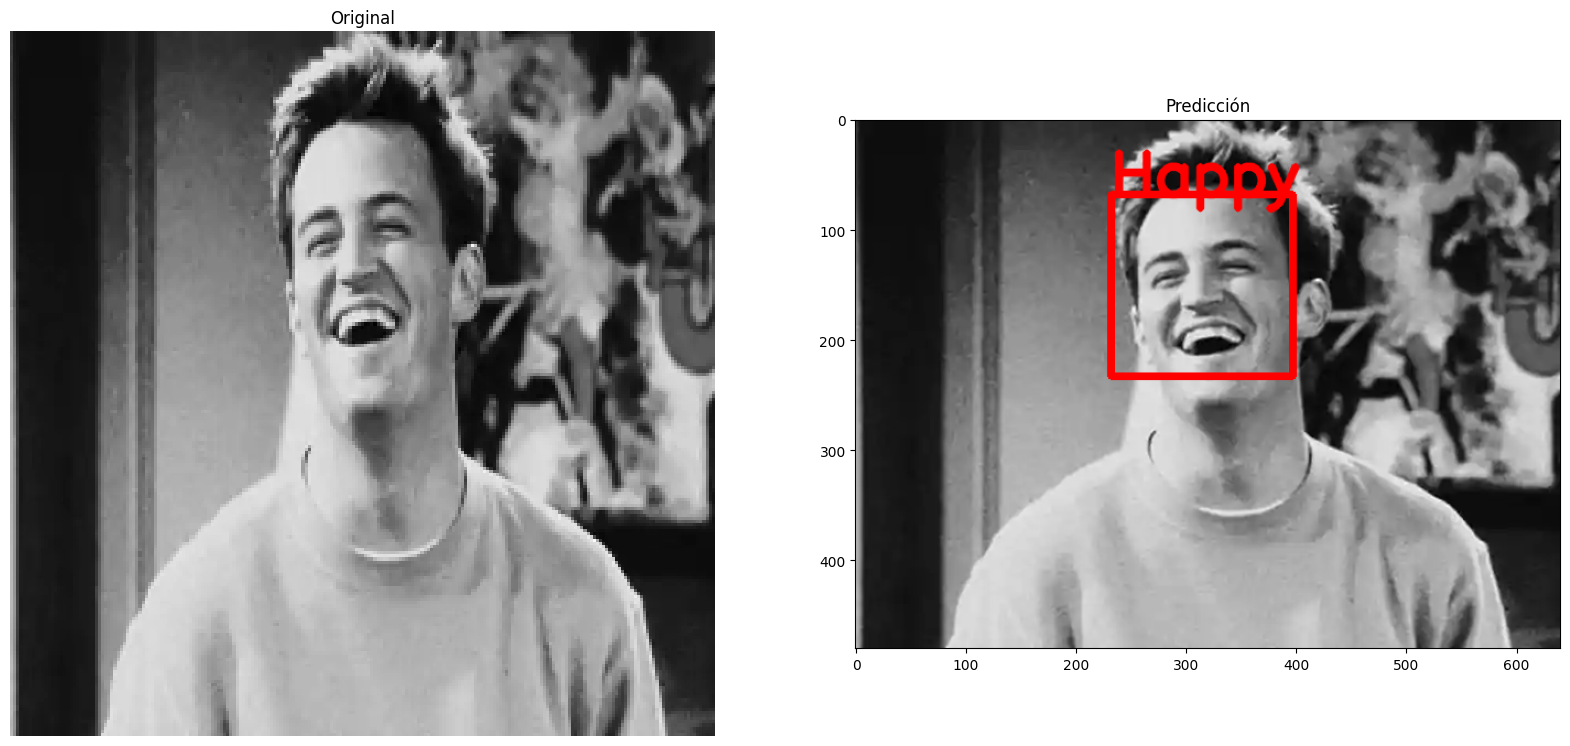

In [ ]:
fig = plt.figure(figsize=(20, 10))

ax1 = fig.add_subplot(1, 2, 1)
plt.title('Original')
plt.axis('off')
ax1.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

ax2 = fig.add_subplot(1, 2, 2)
plt.title('Predicción')
ax2.imshow(full_size_image)

plt.show()

### 10.1 ¿Qué tan segura está la red? 📊 *(añadido)*

La CNN no entrega solo *una* emoción: produce una **probabilidad para cada una de las siete**.
Mirar esa distribución completa es mucho más informativo que quedarse con el `argmax`, porque
revela cuándo el modelo **duda** entre dos emociones parecidas (por ejemplo *Miedo* y *Sorpresa*).

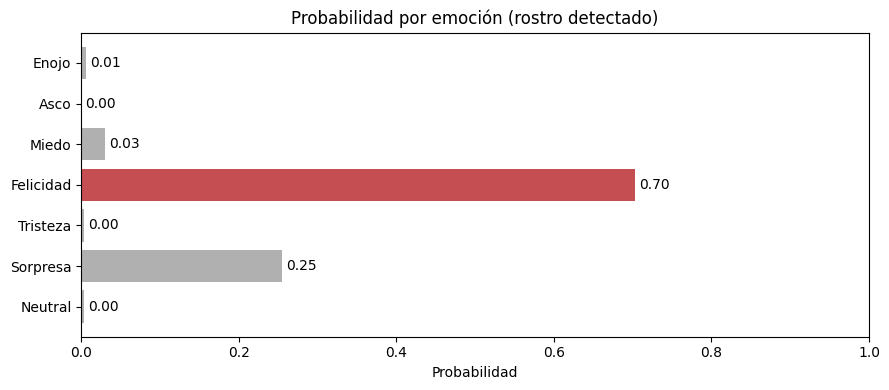

In [ ]:
# Probabilidad asignada a cada emoción para el último rostro detectado
if len(faces) > 0:
    probs = yhat[0]
    colores = ['#C44E52' if i == int(np.argmax(probs)) else '#B0B0B0' for i in range(7)]

    plt.figure(figsize=(9, 4))
    barras = plt.barh(labels_es, probs, color=colores)
    plt.bar_label(barras, fmt='%.2f', padding=3)
    plt.xlim(0, 1)
    plt.title('Probabilidad por emoción (rostro detectado)')
    plt.xlabel('Probabilidad')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No se detectó ningún rostro en la imagen.")

### 10.2 Una función reutilizable y una galería de comparación 🖼️ *(añadido)*

Encapsulamos todo el flujo en una función `reconocer_emocion(ruta)` y, además, mostramos el
**emoji correspondiente** (los íconos vienen en la carpeta `emojis/` del repositorio). Así
podemos comparar de un vistazo el comportamiento del modelo sobre **varias imágenes de prueba**.

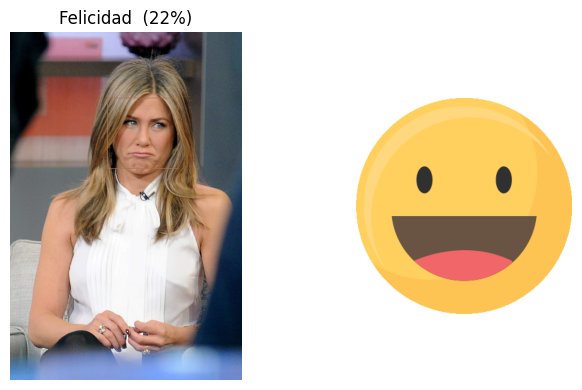

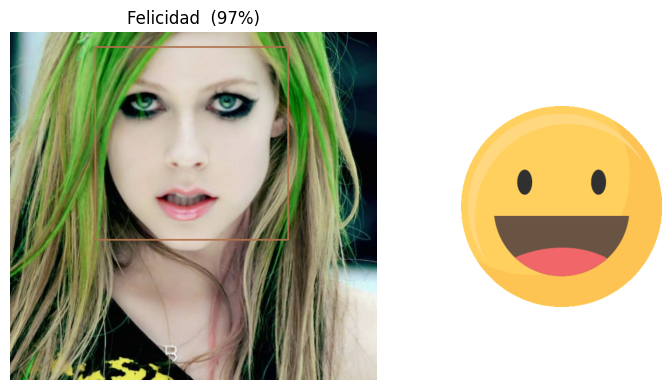

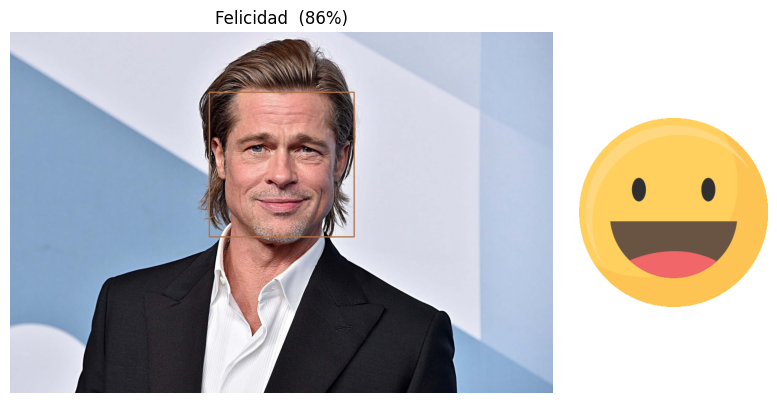

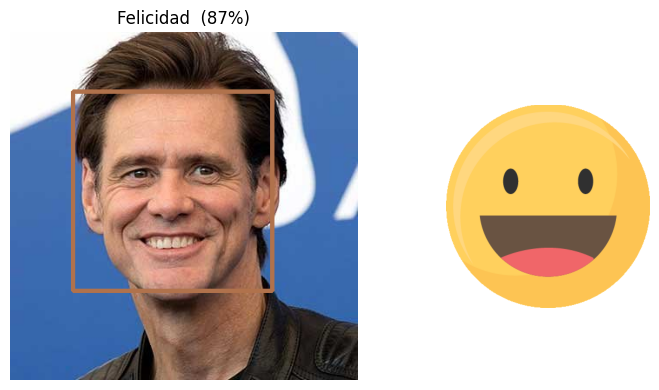

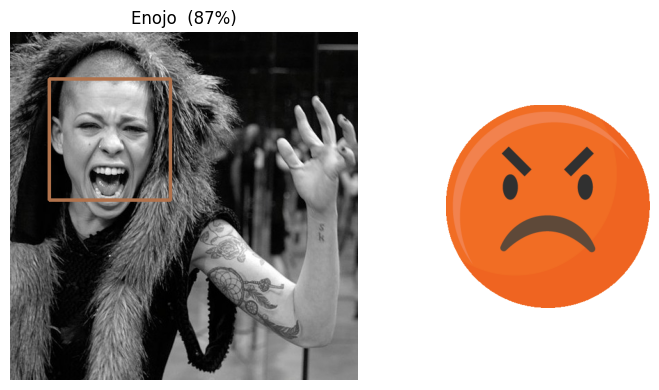

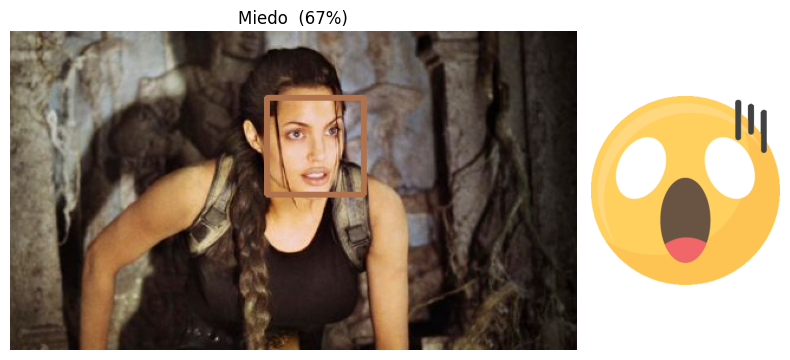

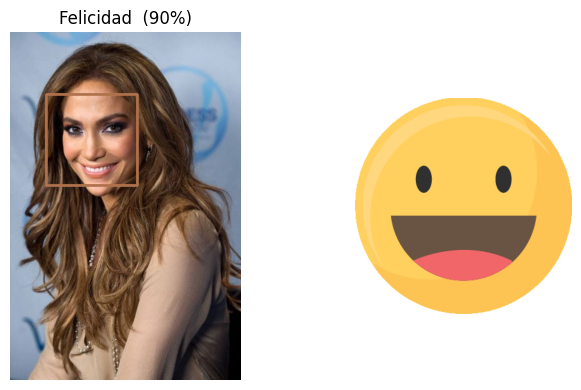

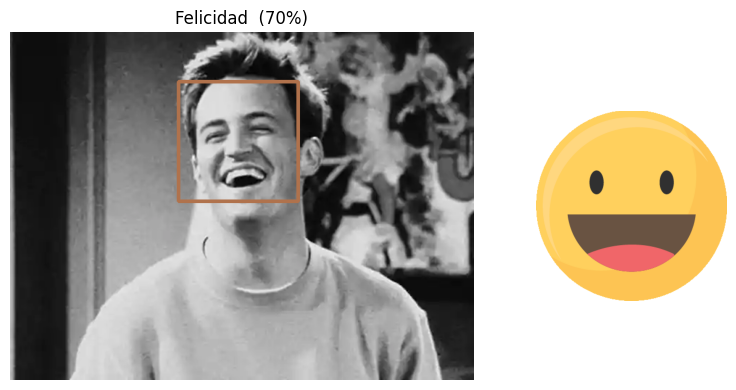

In [ ]:
detector = cv2.CascadeClassifier(
    'facial-emotion-recognition/data_operations/haarcascade_frontalface_default.xml')

def reconocer_emocion(ruta, mostrar=True):
    """Detecta el primer rostro de la imagen y devuelve (emoción_es, probabilidad)."""
    img = cv2.imread(ruta)
    if img is None:
        print("No se pudo cargar:", ruta)
        return None, None
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    rostros = detector.detectMultiScale(gris, 1.3, 10)
    if len(rostros) == 0:
        if mostrar:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off')
            plt.title('Sin rostro detectado'); plt.show()
        return None, None

    x, y, w, h = rostros[0]
    recorte = np.expand_dims(np.expand_dims(cv2.resize(gris[y:y+h, x:x+w], (48, 48)), -1), 0)
    cv2.normalize(recorte, recorte, alpha=0, beta=1, norm_type=cv2.NORM_L2, dtype=cv2.CV_32F)
    p = model.predict(recorte, verbose=0)[0]
    idx = int(np.argmax(p))

    if mostrar:
        emoji = cv2.imread('facial-emotion-recognition/emojis/' + labels[idx] + '.png')
        fig, ejes = plt.subplots(1, 2, figsize=(8, 4),
                                 gridspec_kw={'width_ratios': [3, 1]})
        cv2.rectangle(img, (x, y), (x + w, y + h), (76, 114, 176), 3)
        ejes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ejes[0].axis('off')
        ejes[0].set_title(f'{labels_es[idx]}  ({p[idx]*100:.0f}%)')
        if emoji is not None:
            ejes[1].imshow(cv2.cvtColor(emoji, cv2.COLOR_BGR2RGB))
        ejes[1].axis('off')
        plt.tight_layout(); plt.show()
    return labels_es[idx], float(p[idx])

# Galería: corremos el modelo sobre todas las imágenes de prueba del repositorio
import glob
for ruta in sorted(glob.glob('facial-emotion-recognition/test_pictures/*.jpg')):
    reconocer_emocion(ruta)

## 10. Evaluación global del modelo

Calculamos la **exactitud** sobre el conjunto de prueba completo, comparando la clase predicha
(`argmax` de las probabilidades) con la clase real.

In [ ]:
from keras.models import model_from_json

json_file = open('facial-emotion-recognition/model/fer.json', 'r')
model_json = json_file.read()
json_file.close()
model = model_from_json(model_json)
model.load_weights("facial-emotion-recognition/model/model.weights.h5")

true_y = []
pred_y = []
x_acc = np.load('facial-emotion-recognition/model/X_test.npy')
y_acc = np.load('facial-emotion-recognition/model/y_test.npy')

y_tmp = model.predict(x_acc)
yh = y_tmp.tolist()
yt = y_acc.tolist()
count = 0

for i in range(len(y_acc)):
    yy = max(yh[i])
    yyt = max(yt[i])
    pred_y.append(yh[i].index(yy))
    true_y.append(yt[i].index(yyt))
    if (yh[i].index(yy) == yt[i].index(yyt)):
        count += 1

acc = (count / len(y_acc)) * 100

np.save('facial-emotion-recognition/model/conf_true_y', true_y)
np.save('facial-emotion-recognition/model/conf_pred_y', pred_y)
print("Exactitud: " + str(acc) + "%")

113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step
Exactitud: 64.27974366118696%


## 12. Matriz de confusión

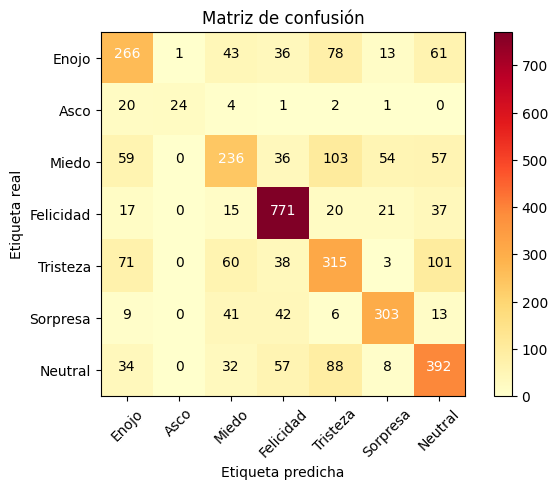

In [ ]:
y_true = np.load('facial-emotion-recognition/model/conf_true_y.npy')
y_pred = np.load('facial-emotion-recognition/model/conf_pred_y.npy')
cm = confusion_matrix(y_true, y_pred)
labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
labels_es = ['Enojo', 'Asco', 'Miedo', 'Felicidad', 'Tristeza', 'Sorpresa', 'Neutral']
title = 'Matriz de confusión'

plt.imshow(cm, interpolation='nearest', cmap=plt.cm.YlOrRd)
plt.title(title)
plt.colorbar()
tick_marks = np.arange(len(labels_es))
plt.xticks(tick_marks, labels_es, rotation=45)
plt.yticks(tick_marks, labels_es)

thresh = cm.max() / 5
for i, j in itertools.product(range(cm.shape[1]), range(cm.shape[0])):
    plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.ylabel('Etiqueta real')      # filas = clase real
plt.xlabel('Etiqueta predicha')  # columnas = clase predicha
plt.show()

### 12.1 Reporte por clase 📋

La exactitud global esconde diferencias  entre clases. El reporte de clasificación desglosa precisión, exhaustividad (recall) y F1 por emoción. Fíjate especialmente en el
F1 bajo de Asco y Miedo: el modelo casi no los reconoce, justamente las clases con menos ejemplos.

In [ ]:
print(classification_report(y_true, y_pred, target_names=labels_es, digits=3))

              precision    recall  f1-score   support

       Enojo      0.559     0.534     0.546       498
        Asco      0.960     0.462     0.623        52
       Miedo      0.548     0.433     0.484       545
   Felicidad      0.786     0.875     0.828       881
    Tristeza      0.515     0.536     0.525       588
    Sorpresa      0.752     0.732     0.742       414
     Neutral      0.593     0.642     0.616       611

    accuracy                          0.643      3589
   macro avg      0.673     0.602     0.623      3589
weighted avg      0.640     0.643     0.638      3589



---


*Cuaderno adaptado para el módulo de Visión por Computador del diplomado de inteligencia artificial aplicada a la industria tecnológica · Universidad de Santiago de Chile.*
---
<a href="https://example.com">02_reconocer_emociones.ipynb</a> © 2026 by <a href="https://example.com">Diego Fischer</a> is licensed under <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">